## Лабораторная работа №1 | Вариант 6

Выполнил: Шитов Артём Сергеевич М8О-316БВ-24

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import random

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(seed=SEED)

### 1. Numpy

1. Создайте единичную матрицу размером 3х3

In [ ]:
I = np.eye(3)
I

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте матрицу 5х5 со значениями 1, 2, 3, 4 ниже диагонали

In [ ]:
A = np.diag([1, 2, 3, 4], k=-1)
A

array([[0, 0, 0, 0, 0],
       [1, 0, 0, 0, 0],
       [0, 2, 0, 0, 0],
       [0, 0, 3, 0, 0],
       [0, 0, 0, 4, 0]])

3. Какой выход будет у данного скрипта

```python
# Author: Jake VanderPlas

print(sum(range(5),-1))
from numpy import *
print(sum(range(5),-1))
```

9, 10 из за перекрытия импортом sum на numpy.sum

4. Как найти самое часто встречаемое значение между двумя массивами?

In [ ]:
a = rng.integers(0, 10, 5)
b = rng.integers(2, 12, 7)
print(a, b, sep='\n')

comb = np.concatenate([a, b])
mode = np.bincount(comb).argmax()
mode

[0 7 6 4 4]
[10  2  8  4  2  7 11]


np.int64(4)

5. Как игнорировать все warnings в numpy(не нужно так делать, но покажи)?

`np.seterr(all="ignore")`

6. Реализуем функцию-генератор, которая генерирует 10 целых чисел и используем ее для построения массива

In [ ]:
def get_random_numbers():
  for _ in range(10):
    yield random.randint(0, 99)

a = np.fromiter(get_random_numbers(), dtype=np.int64, count=10)
a

array([81, 14,  3, 94, 35, 31, 28, 17, 94, 13])

7. Создайте массив случайных чисел размером 10 и отсортируйте его

In [ ]:
a.sort()
a

array([ 3, 13, 14, 17, 28, 31, 35, 81, 94, 94])

8. Создайте случайную матрицу 10х2 которая представляет собой декартовые координаты и преобразуйте их в полярные

In [ ]:
coords = rng.uniform(-10, 10, size=(10, 2))

x = coords[:, 0]
y = coords[:, 1]

r = np.hypot(x, y)
theta = np.arctan2(y, x)

polar = np.column_stack([r, theta])
print(f"Cartesian:\n{coords}\n\nPolar:\n{polar}")

Cartesian:
[[ 5.22279404  5.72128611]
 [-7.43772735 -0.99228124]
 [-2.58403952  8.53529978]
 [ 2.8773024   6.45523227]
 [-1.13171602 -5.45522556]
 [ 1.09169574 -8.72365488]
 [ 6.55262344  2.63328798]
 [ 5.1617548  -2.90948064]
 [ 9.41396049  7.86242243]
 [ 5.56766994 -6.10722584]]

Polar:
[[ 7.74665685  0.83091572]
 [ 7.50362647 -3.00896394]
 [ 8.91788105  1.86477173]
 [ 7.06745306  1.15149749]
 [ 5.57137928 -1.77535016]
 [ 8.79169802 -1.44630151]
 [ 7.06194588  0.38211546]
 [ 5.9252671  -0.51327108]
 [12.26541228  0.69583156]
 [ 8.26420934 -0.83158035]]


9. Создайте структурированный массив который будет описывать пиксель(координату x, y и цвет r,g,b)

In [ ]:
pixel_dtype = np.dtype([
    ('x', np.int32),
    ('y', np.int32),
    ('r', np.uint8),
    ('g', np.uint8),
    ('b', np.uint8),
])

pixel = np.array([(100, 200, 255, 128, 0)], dtype=pixel_dtype)
pixel

array([(100, 200, 255, 128, 0)],
      dtype=[('x', '<i4'), ('y', '<i4'), ('r', 'u1'), ('g', 'u1'), ('b', 'u1')])

10. Как конвертировать тип массив от float32 в int32 in place?

Никак

In [ ]:
a = np.array([1.2, 10., 5.7, 3.4], dtype=np.float32)

b = a.copy()
b.dtype = np.int32
print(b) # Мусор или можно view()

c = a.astype(np.int32)
print(c) # Копирование

[1067030938 1092616192 1085695590 1079613850]
[ 1 10  5  3]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом

Набор данных описывает эффективность учеников в зависимости от некоторых факторов влияющих на обучение и окружение человека.

Файл: `student_perfomance.csv`

```
Hours_Studied - количество часов затраченное на обучение в неделю
Attendance - поцент посещенных занятий
Parental_Involvement - уровень участия родителей в обучении учащегося
Access_to_Resources - доступность ресурсов для обучения
Extracurricular_Activities - участие во внеклассных мероприятиях
Sleep_Hours - количество часов выделяемое на сон в день
Previous_Scores - оценка за первый экзамен
Motivation_Level - уровень мотивации
Internet_Access - доступ к интернету
Tutoring_Sessions - количество посещаемых репетиторских занятий в месяц.
Family_Income - доход семьи
Teacher_Quality - насколько качественно преподает учитель
School_Type - тип школы(частная, обычная)
Peer_Influence - влияние сверстников
Physical_Activity - физическая активность
Learning_Disabilities - наличие проблем с обучаемостью
Parental_Education_Level - уровень образования родителей
Distance_from_Home - дистанция от дома до школы
Gender - пол
Exam_Score - оценка на конечном экзамене
```

In [ ]:
df = pd.read_csv("/content/sample_data/student_perfomance.csv")
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

1. Посчитайте среднее кол-во часов уделяемое на сон студентами

In [ ]:
df["Sleep_Hours"].mean()

np.float64(7.029060087785682)

2. Сколько процентов студентов посещают внеклассовые активности?

In [ ]:
df["Extracurricular_Activities"].value_counts(normalize=True)["Yes"] * 100

np.float64(59.60345088542455)

3. Правда ли, что в среднем девушки сдают экзамены лучше, чем мужчины

In [ ]:
is_male = df["Gender"].eq("Male")
male_mean = df[is_male]["Exam_Score"].mean()
female_mean = df[~is_male]["Exam_Score"].mean()
female_mean > male_mean

np.True_

4. Выведите 25 и 75 перцентили времени сна студентов

In [ ]:
df["Sleep_Hours"].quantile(0.25), df["Sleep_Hours"].quantile(0.75)

(np.float64(6.0), np.float64(8.0))

5. Правда ли, что те, кто спит больше(75 перцентиль и выше) сдает экзамен лучше, чем студенты с недосыпом(25 перцентиль и меньше)

In [ ]:
q75 = df["Sleep_Hours"].quantile(0.75)
q25 = df["Sleep_Hours"].quantile(0.25)

sleep_well_mean = df[df["Sleep_Hours"].ge(q75)]["Exam_Score"].mean()
sleep_bad_mean = df[df["Sleep_Hours"].le(q25)]["Exam_Score"].mean()

sleep_well_mean > sleep_bad_mean

np.False_

6. Влияет ли физическая активность на результаты экзамена?

In [ ]:
df[["Physical_Activity", "Exam_Score"]].corr()

,Physical_Activity,Exam_Score
Physical_Activity,1.000000,0.027824
Exam_Score,0.027824,1.000000


In [ ]:
df[["Physical_Activity", "Exam_Score"]].corr(method="spearman")

,Physical_Activity,Exam_Score
Physical_Activity,1.00000,0.02915
Exam_Score,0.02915,1.00000


Вывод: вроде нет

7. Правда ли, что студенты, чьи родители имеют высшее образование(College || Postgraduate), сдают экзамены лучше, чем остальные?

In [ ]:
mask = df["Parental_Education_Level"].eq("College") | df["Parental_Education_Level"].eq("Postgraduate")

educated_parents_mean = df[mask]["Exam_Score"].mean()
uneducated_parents_mean = df[~mask]["Exam_Score"].mean()

educated_parents_mean > uneducated_parents_mean

np.True_

8. Как влияет участие родителей на результаты экзаменов

In [ ]:
df_encoded = pd.get_dummies(df, columns=["Parental_Involvement"])
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Hours_Studied                6607 non-null   int64 
 1   Attendance                   6607 non-null   int64 
 2   Access_to_Resources          6607 non-null   object
 3   Extracurricular_Activities   6607 non-null   object
 4   Sleep_Hours                  6607 non-null   int64 
 5   Previous_Scores              6607 non-null   int64 
 6   Motivation_Level             6607 non-null   object
 7   Internet_Access              6607 non-null   object
 8   Tutoring_Sessions            6607 non-null   int64 
 9   Family_Income                6607 non-null   object
 10  Teacher_Quality              6529 non-null   object
 11  School_Type                  6607 non-null   object
 12  Peer_Influence               6607 non-null   object
 13  Physical_Activity            6607

In [ ]:
for col in ["Parental_Involvement_High", "Parental_Involvement_Low", "Parental_Involvement_Medium"]:
  display(df_encoded[[col, "Exam_Score"]].corr())

,Parental_Involvement_High,Exam_Score
Parental_Involvement_High,1.000000,0.140396
Exam_Score,0.140396,1.000000


,Parental_Involvement_Low,Exam_Score
Parental_Involvement_Low,1.000000,-0.113602
Exam_Score,-0.113602,1.000000


,Parental_Involvement_Medium,Exam_Score
Parental_Involvement_Medium,1.000000,-0.035978
Exam_Score,-0.035978,1.000000


In [ ]:
for col in ["Parental_Involvement_Low", "Parental_Involvement_Medium", "Parental_Involvement_High"]:
  display(df_encoded[[col, "Exam_Score"]].corr(method="spearman"))

,Parental_Involvement_Low,Exam_Score
Parental_Involvement_Low,1.000000,-0.129332
Exam_Score,-0.129332,1.000000


,Parental_Involvement_Medium,Exam_Score
Parental_Involvement_Medium,1.000000,-0.031328
Exam_Score,-0.031328,1.000000


,Parental_Involvement_High,Exam_Score
Parental_Involvement_High,1.000000,0.149211
Exam_Score,0.149211,1.000000


Вывод: нет прямой связи, но при низкой и средней результат экза уменьшается, а при высокой растет

9. Правда ли, что в семьях с доходом больше среднего дети сдают экзамены лучше?

In [ ]:
high_family_income = df["Family_Income"].eq("High")

res_le_mean = df[~high_family_income]["Exam_Score"].mean()
res_gt_mean = df[high_family_income]["Exam_Score"].mean()

res_gt_mean > res_le_mean

np.True_

10. Посчитайте долю студентов сдавших экзамен на более чем 70 баллов в семьях с низким доходом и отсутствием доступа к интернету

In [ ]:
mask = df["Family_Income"].eq("Low") & df["Internet_Access"].eq("No")
masked_df = df[mask].copy()
masked_df["Exam_Score_Greater_Than_70"] = masked_df["Exam_Score"].gt(70)

masked_df["Exam_Score_Greater_Than_70"].value_counts(normalize=True).iloc[1] * 100

np.float64(8.056872037914692)

### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Правда ли, что количество часов затрачиваемых на сон распределено примерно нормально?

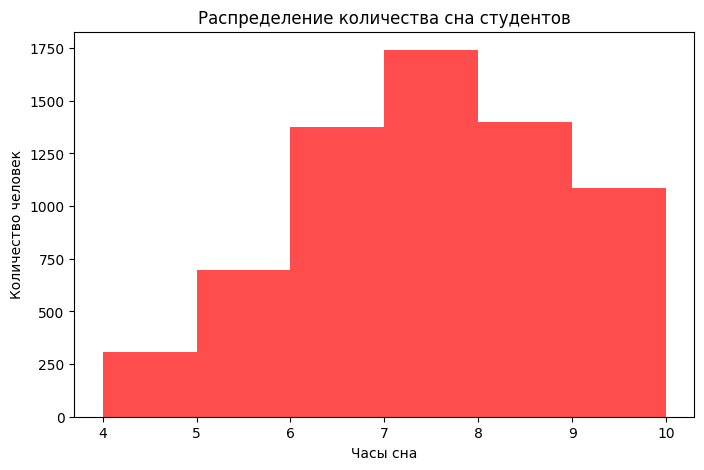

In [ ]:
fig, ax = plt.subplots(figsize=(8,5))

ax.hist(df['Sleep_Hours'], bins='auto', color='red', alpha=0.7)

ax.set_title("Распределение количества сна студентов")
ax.set_xlabel("Часы сна")
ax.set_ylabel("Количество человек")

plt.show()

Вывод: да, примерно верно

2. Постройте гистограмму распределения количества часов затрачиваемых на обучение среди мальчиков и девочек

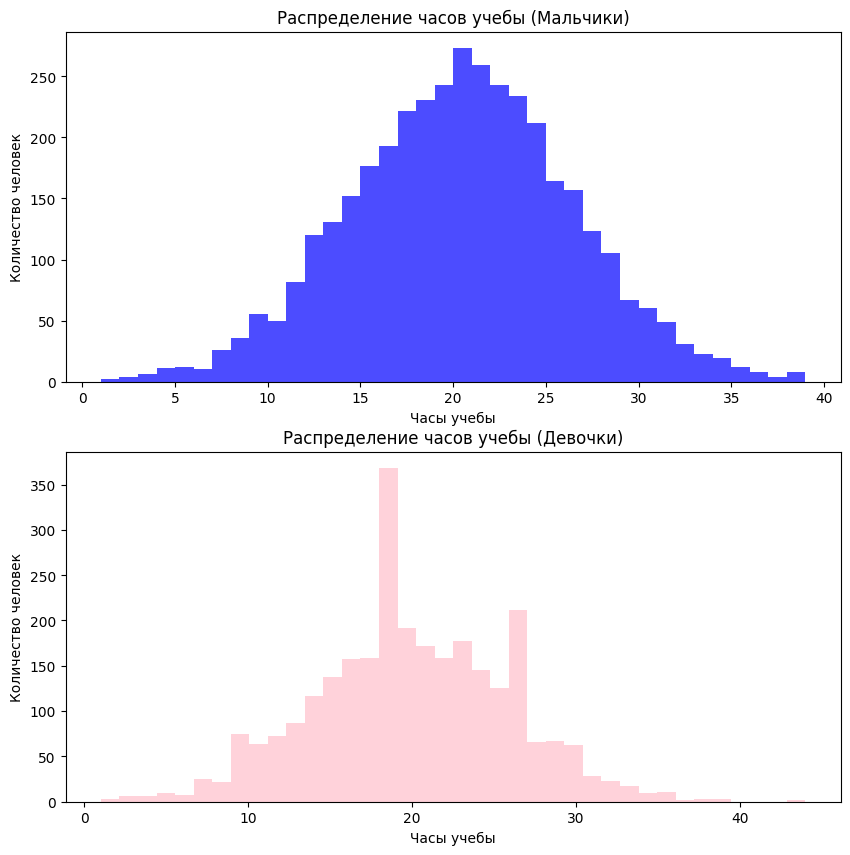

In [ ]:
studying_hours_male = df[df["Gender"].eq("Male")]["Hours_Studied"]
studying_hours_female = df[df["Gender"].eq("Female")]["Hours_Studied"]

fig, ax = plt.subplots(2, figsize=(10, 10))

ax[0].hist(studying_hours_male, bins='auto', color="blue", alpha=0.7)
ax[0].set_title("Распределение часов учебы (Мальчики)")
ax[0].set_xlabel("Часы учебы")
ax[0].set_ylabel("Количество человек")

ax[1].hist(studying_hours_female, bins='auto', color="pink", alpha=0.7)
ax[1].set_title("Распределение часов учебы (Девочки)")
ax[1].set_xlabel("Часы учебы")
ax[1].set_ylabel("Количество человек")

plt.show()

3. Как зависит результат конечного экзамена от результата первого экзамена

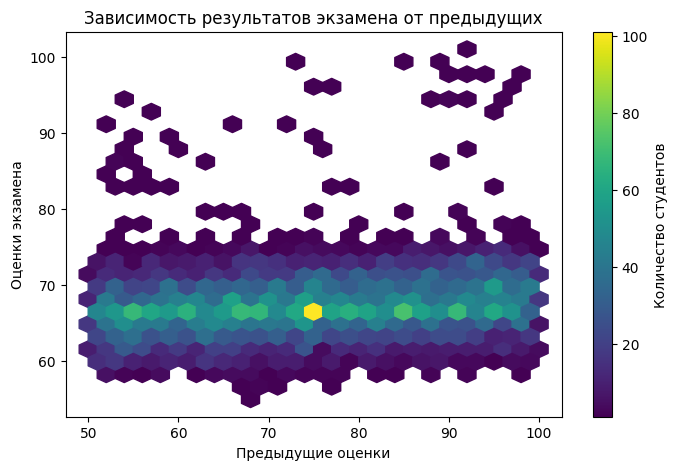

In [ ]:
prev_scores = df["Previous_Scores"]
exam_scores = df["Exam_Score"]

fig, ax = plt.subplots(figsize=(8, 5))

hb = ax.hexbin(prev_scores, exam_scores, gridsize=25, cmap='viridis',mincnt=1)

ax.set_title("Зависимость результатов экзамена от предыдущих")
ax.set_xlabel("Предыдущие оценки")
ax.set_ylabel("Оценки экзамена")

plt.colorbar(hb, label="Количество студентов")
plt.show()

Вывод: никак

4. Постройте box plot отображающий распределение количества сна детей сдавших экзамены на оценку ниже и выше 85 баллов

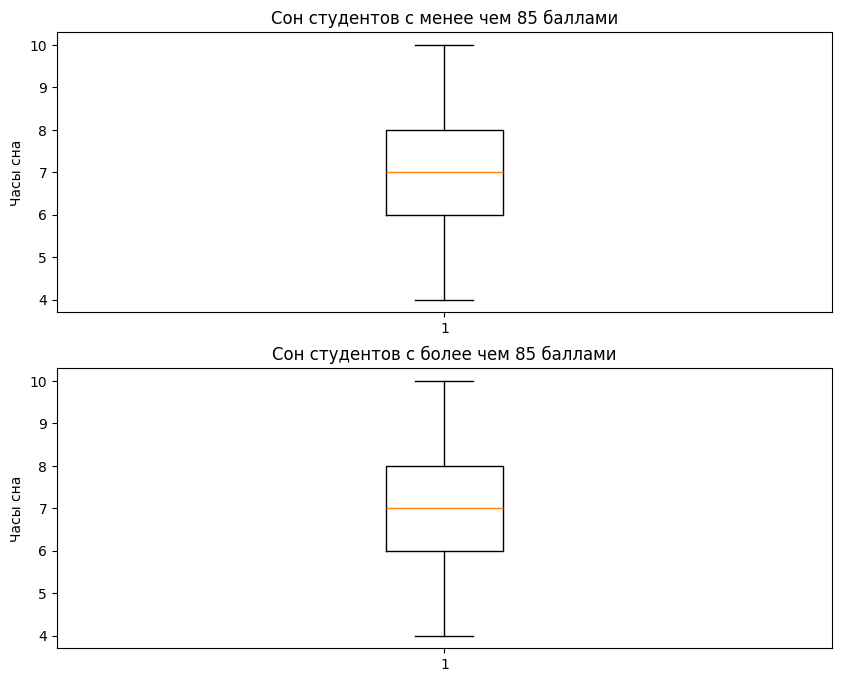

In [ ]:
has_score_lt_85 = df[df["Exam_Score"].lt(85)]["Sleep_Hours"]
has_score_gt_85 = df[df["Exam_Score"].gt(85)]["Sleep_Hours"]

fix, ax = plt.subplots(2, figsize=(10, 8))

ax[0].boxplot(has_score_lt_85)
ax[0].set_title("Сон студентов с менее чем 85 баллами")
ax[0].set_ylabel("Часы сна")

ax[1].boxplot(has_score_gt_85)
ax[1].set_title("Сон студентов с более чем 85 баллами")
ax[1].set_ylabel("Часы сна")

plt.show()

5. Правда ли, что количество посещаемых занятий с репетитором в месяц напрямую влияет на балл в конечном экзамене?

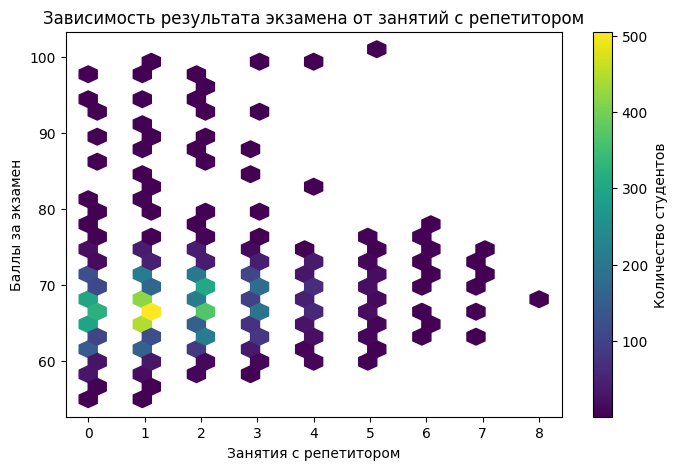

In [ ]:
tutoring_sessions = df["Tutoring_Sessions"]
exam_scores = df["Exam_Score"]

fig, ax = plt.subplots(figsize=(8, 5))

hb = ax.hexbin(tutoring_sessions, exam_scores, gridsize=25, cmap='viridis',mincnt=1)
ax.set_title("Зависимость результата экзамена от занятий с репетитором")
ax.set_xlabel("Занятия с репетитором")
ax.set_ylabel("Баллы за экзамен")

plt.colorbar(hb, label="Количество студентов")
plt.show()

Вывод: неправда

6. Как физическая активность влияет на успеваемость?

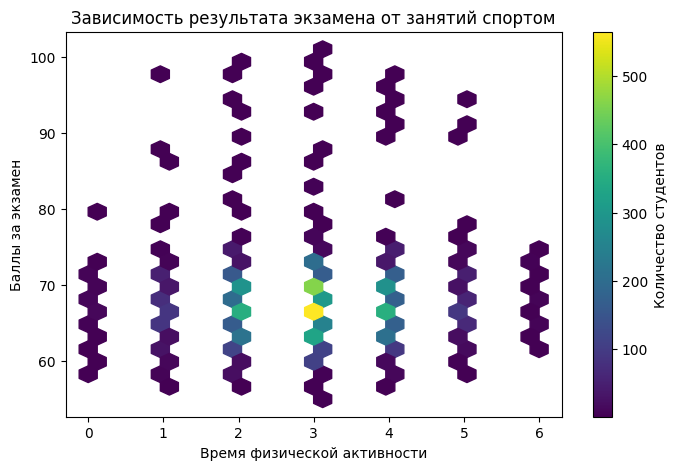

In [ ]:
sports_time = df["Physical_Activity"]
exam_scores = df["Exam_Score"]

fig, ax = plt.subplots(figsize=(8, 5))

hb = ax.hexbin(sports_time, exam_scores, gridsize=25, cmap='viridis',mincnt=1)
ax.set_title("Зависимость результата экзамена от занятий спортом")
ax.set_xlabel("Время физической активности")
ax.set_ylabel("Баллы за экзамен")

plt.colorbar(hb, label="Количество студентов")
plt.show()

Вывод: среди тех, кто лучше всех сдает экзамен (70+ баллов), больше ребят, занимающихся спортом, так что да

7. Постройте HeatMap где ось Х - процент посещаемость, Y - количество занятий с репетитором, а Z - балл за итоговый экзамен*

\* Задание на доп. балл

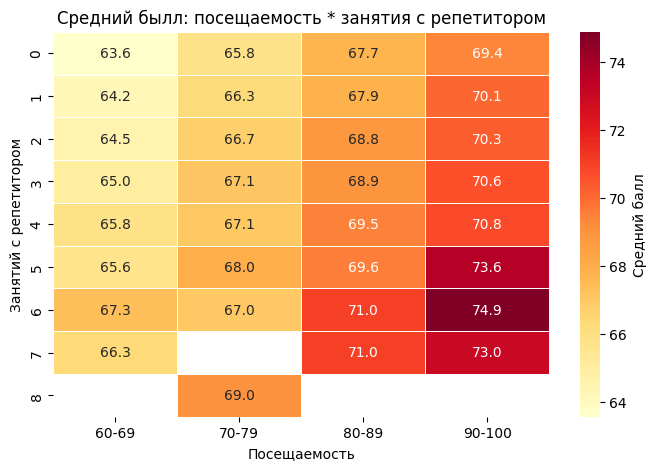

In [ ]:
df["Attendance_Bin"] = pd.cut(df["Attendance"],
                              bins=[60, 70, 80, 90, 100],
                              labels=['60-69', '70-79', '80-89', '90-100'],
                              include_lowest=True)

pivot = df.pivot_table(values="Exam_Score", index="Tutoring_Sessions",
                       columns="Attendance_Bin", aggfunc="mean", observed=False)

fig, ax = plt.subplots(figsize=(8, 5))

sns.heatmap(
    pivot,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={"label": "Средний балл"}
)

ax.set_title("Средний былл: посещаемость * занятия с репетитором")
ax.set_xlabel("Посещаемость")
ax.set_ylabel("Занятий с репетитором")

plt.show()